<a href="https://colab.research.google.com/github/JSEFERINO/Curso_Estadistica/blob/main/Laboratorio_13_Diego_Alejandro_Tous_Aponte_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a name="inicio"></a>

<div style="background: linear-gradient(135deg, #7A94B8 0%, #5ECCC3 50%, #FDB913 100%); padding: 50px 30px; border-radius: 18px; text-align: center; color: white; box-shadow: 0 12px 30px rgba(122,148,184,0.35);">
  <p style="font-size: 16px; letter-spacing: 3px; margin: 0;">ESTADÍSTICA Y PROBABILIDAD</p>
  <h1 style="color: white; font-size: 40px; margin: 14px 0; text-shadow: 2px 3px 8px rgba(0,0,0,0.25);">Laboratorio 13</h1>
  <h2 style="color: white; font-size: 24px; margin: 0;">Modelos probabilísticos discretos en Python</h2>
  <hr style="border: 0; height: 2px; background: rgba(255,255,255,0.7); width: 60%; margin: 26px auto;">
  <p style="font-size: 20px; font-weight: 600; margin: 0;">Diego Alejandro Tous Aponte</p>
</div>

## **Índice**

1. [Preparación del entorno](#preparacion)
2. [Función para graficar distribuciones discretas](#funcion)
3. [Exploración de modelos probabilísticos discretos](#exploracion)
   - [3.1 Distribución de Bernoulli](#bernoulli)
   - [3.2 Distribución Binomial](#binomial)
   - [3.3 Distribución Binomial Negativa](#binneg)
   - [3.4 Distribución de Poisson](#poisson)
   - [3.5 Distribución Hipergeométrica](#hipergeo)
4. [Ejercicios propuestos](#ejercicios)

### **Laboratorio 13: Modelos Probabilísticos Discretos en Python**

**Objetivo General:**
Aprender a utilizar Python y sus librerías científicas (NumPy, SciPy, Matplotlib) para modelar, calcular y graficar las distribuciones de probabilidad discretas más importantes: Bernoulli, Binomial, Binomial Negativa, Poisson e Hipergeométrica.

**Herramientas a Utilizar:**
- Google Colab o Jupyter Notebook
- Python 3
- Librerías: `numpy`, `scipy.stats`, `matplotlib.pyplot`

<a name="preparacion"></a>

### **Parte 1: Preparación del Entorno**

Antes de comenzar, debemos importar las librerías que nos permitirán realizar los cálculos y las gráficas.

**Código para ejecutar:**

[⬆️ Volver al inicio](#inicio)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
from matplotlib.lines import Line2D
from scipy.stats import binom, nbinom, poisson, hypergeom

NOMBRE = "Diego Alejandro Tous Aponte"

# ---------- Paleta futurista (modo oscuro / neón) ----------
BG        = "#070B1A"   # fondo de la figura
PANEL     = "#0E1530"   # fondo de ejes y panel
GRILLA    = "#1C2748"
NEON_AZUL = "#00D4FF"   # barras normales
NEON_ROSA = "#FF2E88"   # región pedida
NEON_LIMA = "#B6FF3B"   # media y banda de desviación estándar
NEON_VIOL = "#A78BFA"   # función de distribución acumulada F(x)
TEXTO     = "#E6F1FF"
SUAVE     = "#7F93B8"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": BG,
    "savefig.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": GRILLA,
    "axes.labelcolor": TEXTO,
    "axes.labelsize": 11.5,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRILLA,
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,
    "xtick.color": SUAVE,
    "ytick.color": SUAVE,
    "text.color": TEXTO,
    "mathtext.fontset": "dejavusans",
    "font.size": 11,
})

print("¡Entorno listo para el laboratorio!")

¡Entorno listo para el laboratorio!


[⬆️ Volver al inicio](#inicio)

<a name="funcion"></a>

### **Parte 2: Función de Ayuda para Graficar**

Para no repetir código, crearemos una función que nos permita graficar cualquier distribución discreta de manera sencilla. Esta función recibirá los valores posibles (eje x) y sus probabilidades (eje y).

**Código para ejecutar:**

[⬆️ Volver al inicio](#inicio)

In [ ]:
# @title **A. Función para Graficar Distribuciones Discretas**
def plot_distribution(dist_name, values, pmf, title, xlabel="Valores (k)",
                      resaltar=None, etiqueta=None, ancho=None,
                      mostrar_valores=None, momentos=None, figsize=(13, 6.6)):
    """
    Grafica una PMF con un panel estadístico: barras, función acumulada F(x),
    media (μ), banda de ±1σ y un panel lateral con los estadísticos.

    Args:
        dist_name (str): Nombre de la distribución.
        values (array): Valores posibles de la variable aleatoria.
        pmf (array): Probabilidades asociadas a cada valor.
        title (str): Título del gráfico.
        xlabel (str): Texto del eje x.
        resaltar (array de bool, opcional): Barras resaltadas en rosa neón.
        etiqueta (str, opcional): Probabilidad calculada, p. ej. "$P(X \\leq 4) = 0.9$".
        ancho (float, opcional): Ancho de las barras.
        mostrar_valores (bool, opcional): Valor sobre cada barra (por defecto, si hay <= 16).
        momentos (tuple, opcional): (media, varianza) teóricas; útil si el eje x está truncado.
    """
    values = np.asarray(values)
    pmf = np.asarray(pmf)
    mascara = np.zeros(len(values), dtype=bool) if resaltar is None else np.asarray(resaltar, dtype=bool)
    if ancho is None:
        ancho = 0.45 if len(values) <= 3 else 0.72
    if mostrar_valores is None:
        mostrar_valores = len(values) <= 16

    # ---- Estadísticos calculados a partir de la PMF ----
    media = float(np.sum(values * pmf))
    varianza = float(np.sum((values - media) ** 2 * pmf))
    if momentos is not None:                  # momentos teóricos exactos
        media, varianza = float(momentos[0]), float(momentos[1])
    sigma = np.sqrt(varianza)
    moda = values[int(np.argmax(pmf))]
    cdf = np.cumsum(pmf)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[3.7, 1.15], wspace=0.30)
    ax = fig.add_subplot(gs[0])
    axp = fig.add_subplot(gs[1])
    fig.subplots_adjust(left=0.075, right=0.985, top=0.80, bottom=0.21)

    # ---- Banda ±1σ y línea de la media ----
    ax.axvspan(media - sigma, media + sigma, color=NEON_LIMA, alpha=0.07, zorder=1)
    ax.axvline(media, color=NEON_LIMA, ls="--", lw=1.4, alpha=0.9, zorder=2)

    # ---- Barras con efecto de brillo (glow) ----
    colores = np.where(mascara, NEON_ROSA, NEON_AZUL)
    for extra, alfa in ((0.30, 0.10), (0.16, 0.16)):
        ax.bar(values, pmf, width=ancho + extra, color=colores, alpha=alfa, linewidth=0, zorder=3)
    ax.bar(values, pmf, width=ancho, color=colores, alpha=0.88,
           edgecolor=colores, linewidth=1.2, zorder=4)

    if mostrar_valores:
        for v, p in zip(values, pmf):
            ax.text(v, p + pmf.max() * 0.018, f"{p:.3f}", ha="center", va="bottom",
                    fontsize=8.5, color=TEXTO, alpha=0.85, family="monospace", zorder=6)

    ax.set_xlabel(xlabel, labelpad=8)
    ax.set_ylabel("Probabilidad  $P(X=k)$", labelpad=8, color=NEON_AZUL)
    paso = int(np.ceil(len(values) / 20))      # evita que las marcas se encimen
    ax.set_xticks(values[::paso])
    ax.set_ylim(0, pmf.max() * 1.22)
    ax.set_xlim(values.min() - 0.8, values.max() + 0.8)
    ax.grid(axis="y", zorder=0)
    ax.tick_params(length=0)

    # ---- Función de distribución acumulada F(x) en el eje derecho ----
    ax2 = ax.twinx()
    ax2.step(values, cdf, where="mid", color=NEON_VIOL, lw=2, zorder=5)
    ax2.plot(values, cdf, "o", color=NEON_VIOL, ms=3.5, zorder=5)
    ax2.set_ylim(0, 1.08)
    ax2.set_ylabel("Acumulada  $F(x)=P(X\\leq x)$", labelpad=8, color=NEON_VIOL)
    ax2.tick_params(length=0, colors=NEON_VIOL)
    for lado in ("top", "left", "bottom"):
        ax2.spines[lado].set_visible(False)
    ax2.spines["right"].set_color(GRILLA)

    # ---- Leyenda inferior ----
    handles = []
    if mascara.any():
        handles.append(Patch(facecolor=NEON_ROSA, label="Región pedida"))
    handles += [Patch(facecolor=NEON_AZUL, label="PMF  P(X=k)"),
                Line2D([0], [0], color=NEON_VIOL, lw=2, marker="o", ms=4, label="CDF  F(x)"),
                Line2D([0], [0], color=NEON_LIMA, lw=1.4, ls="--", label=f"Media  μ = {media:.2f}"),
                Patch(facecolor=NEON_LIMA, alpha=0.25, label="Banda  μ ± σ")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13),
              ncol=len(handles), frameon=False, fontsize=9.5, labelcolor=TEXTO,
              handlelength=1.6, columnspacing=1.6)

    # ---- Encabezado: título, nombre y línea de acento ----
    fig.text(0.075, 0.925, title, fontsize=18, fontweight="bold", color=TEXTO, va="center")
    fig.text(0.075, 0.862, "▌ " + NOMBRE.upper(), fontsize=11.5, family="monospace",
             fontweight="bold", color=NEON_ROSA, va="center")
    fig.add_artist(Line2D([0.075, 0.985], [0.825, 0.825], color=NEON_AZUL, lw=1.3, alpha=0.8))
    fig.add_artist(Line2D([0.075, 0.20], [0.825, 0.825], color=NEON_AZUL, lw=3.2))
    fig.text(0.985, 0.025, "ESTADÍSTICA Y PROBABILIDAD  ·  LABORATORIO 13  ·  " + NOMBRE,
             ha="right", fontsize=8, family="monospace", color=SUAVE)

    # ---- Panel lateral de estadísticos ----
    axp.set_xlim(0, 1); axp.set_ylim(0, 1); axp.axis("off")
    axp.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.04",
                                 transform=axp.transAxes, facecolor=PANEL,
                                 edgecolor=NEON_AZUL, linewidth=1.3, clip_on=False))
    y = 0.93
    if etiqueta is not None:
        lhs, rhs = etiqueta.strip("$").rsplit("=", 1)
        axp.text(0.08, y, "▌RESULTADO", fontsize=9.5, family="monospace", color=NEON_AZUL, va="center")
        axp.text(0.5, y - 0.11, f"${lhs.strip()}$ =", fontsize=14, color=TEXTO, ha="center", va="center")
        axp.text(0.5, y - 0.22, f"${rhs.strip()}$", fontsize=21, color=NEON_ROSA, ha="center", va="center")
        axp.plot([0.08, 0.92], [y - 0.31, y - 0.31], color=GRILLA, lw=1)
        y = y - 0.40
    axp.text(0.08, y, "▌ESTADÍSTICOS", fontsize=9.5, family="monospace", color=NEON_AZUL, va="center")
    filas = [("μ  =", f"{media:.3f}", NEON_LIMA), ("σ² =", f"{varianza:.3f}", TEXTO),
             ("σ  =", f"{sigma:.3f}", TEXTO), ("Moda", f"{moda}", TEXTO)]
    for i, (nom, val, col) in enumerate(filas):
        yy = y - 0.11 - i * 0.088
        axp.text(0.10, yy, nom, fontsize=11.5, family="monospace", color=SUAVE, va="center")
        axp.text(0.92, yy, val, fontsize=11.5, family="monospace", color=col, ha="right", va="center")
    axp.text(0.08, 0.04, dist_name.upper(), fontsize=9, family="monospace",
             color=SUAVE, va="center")

    plt.show()

[⬆️ Volver al inicio](#inicio)

<a name="exploracion"></a>

### **Parte 3: Exploración de Modelos Probabilísticos Discretos**

A continuación, exploraremos cada distribución con un ejemplo práctico.

<a name="bernoulli"></a>

#### **3.1. Distribución de Bernoulli**

**Definición:** Modela un experimento con dos únicos resultados posibles: "éxito" (1) o "fracaso" (0). La probabilidad de éxito se denota como *p*.

- **Función de Probabilidad:** $P(X=k) = p^k (1-p)^{1-k}$, para $k = 0, 1$.
- **Media (Esperanza):** $E(X) = p$
- **Varianza:** $Var(X) = p(1-p)$

**Ejemplo:** Lanzamiento de una moneda cargada una vez. Sea X = 1 si sale cara, 0 si sale sello. Sea $p=0.58$ la probabilidad de obtener cara (moneda cargada).

**Código para ejecutar:**

[⬆️ Volver al inicio](#inicio)

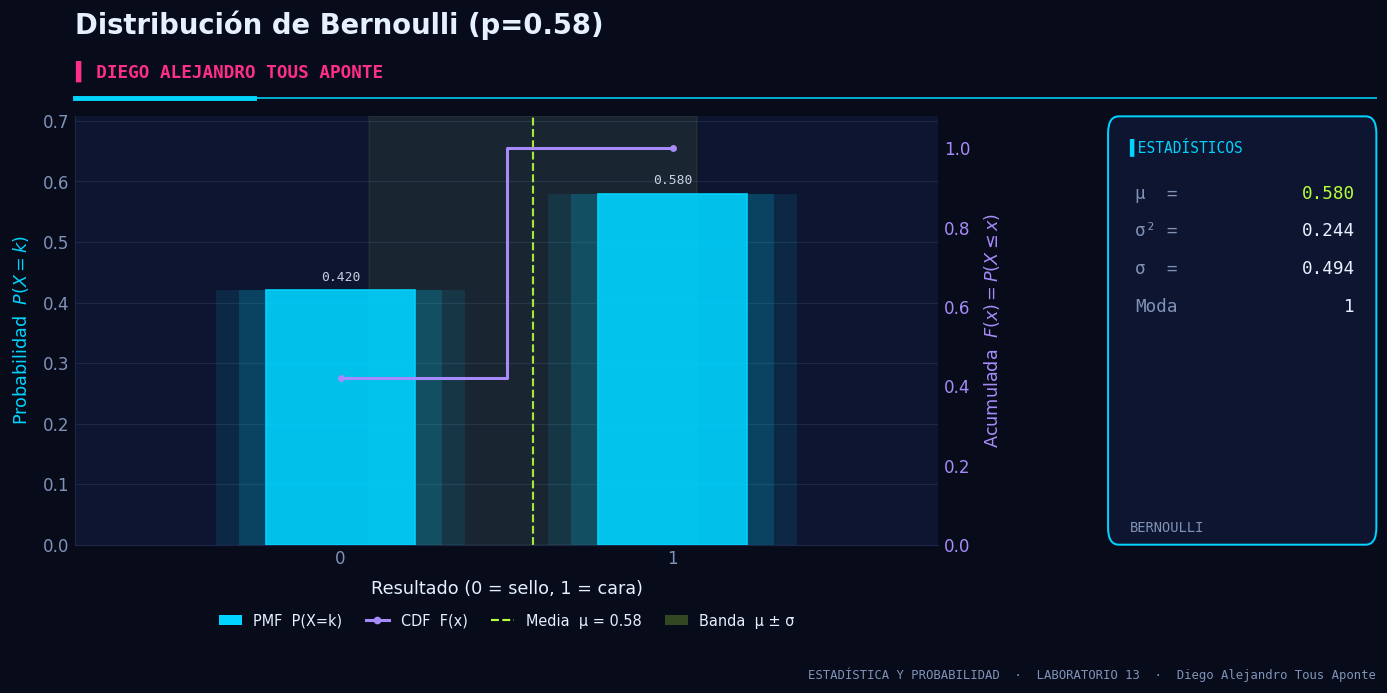

Media (Esperanza): 0.58
Varianza: 0.2436


In [ ]:
# @title **B1. Ejemplo de Distribución de Bernoulli**
n_bernoulli = 1 # Un solo ensayo
p_bernoulli = 0.58 # Probabilidad de éxito (cara) de la moneda cargada

x_bernoulli = np.arange(0, n_bernoulli + 1)
pmf_bernoulli = binom.pmf(x_bernoulli, n_bernoulli, p_bernoulli)

plot_distribution("Bernoulli", x_bernoulli, pmf_bernoulli, f"Distribución de Bernoulli (p={p_bernoulli})",
                  xlabel="Resultado (0 = sello, 1 = cara)")
print(f"Media (Esperanza): {n_bernoulli * p_bernoulli}")
print(f"Varianza: {n_bernoulli * p_bernoulli * (1 - p_bernoulli)}")

[⬆️ Volver al inicio](#inicio)

<a name="binomial"></a>

#### **3.2. Distribución Binomial**

**Definición:** Modela el número de éxitos en *n* ensayos independientes de Bernoulli. Cada ensayo tiene una probabilidad de éxito *p*.

- **Función de Probabilidad:** $P(X=k) = \binom{n}{k} p^k (1-p)^{n-k}$, donde $\binom{n}{k}$ es el coeficiente binomial.
- **Media (Esperanza):** $E(X) = n \cdot p$
- **Varianza:** $Var(X) = n \cdot p \cdot (1-p)$

**Ejemplo:** Lanzar una moneda 10 veces. Sea X = número de caras. $n=10$, $p=0.5$.

**Código para ejecutar:**

[⬆️ Volver al inicio](#inicio)

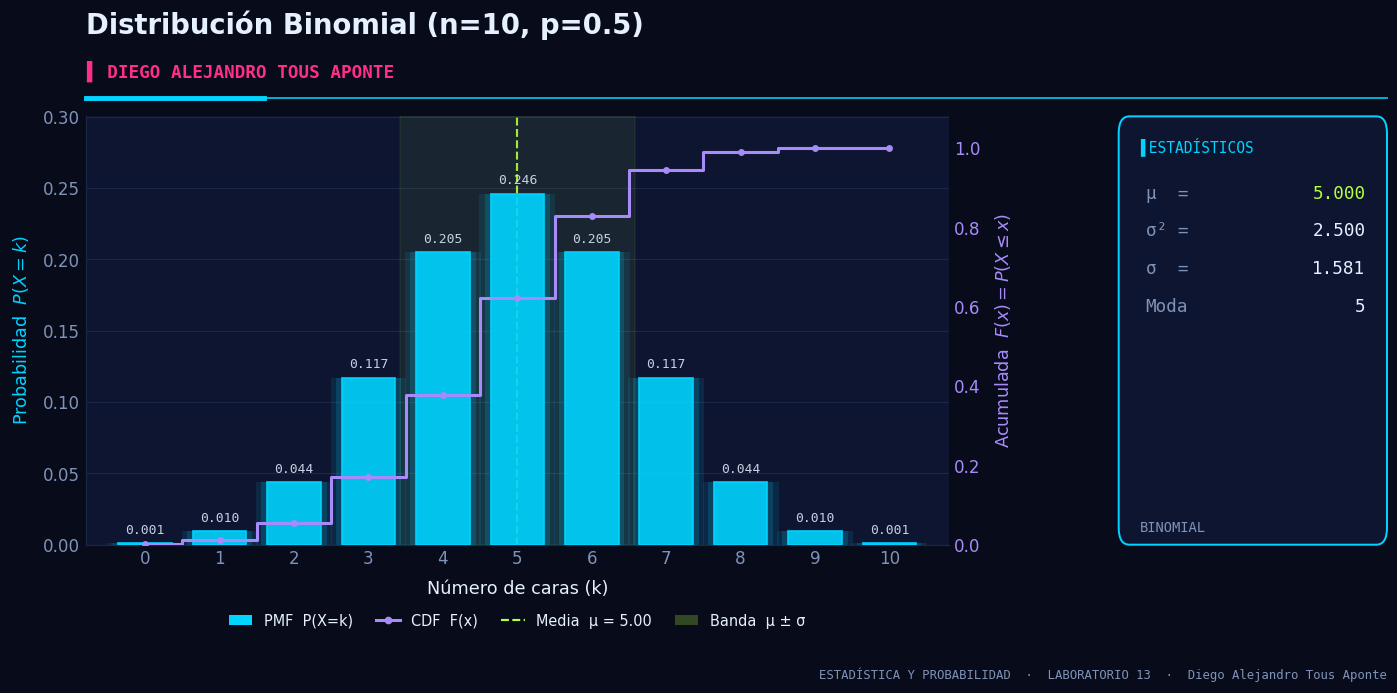

Media (Esperanza): 5.0
Varianza: 2.5


In [ ]:
# @title **B2. Ejemplo de Distribución Binomial**
n_binom = 10 # Número de ensayos
p_binom = 0.5 # Probabilidad de éxito en cada ensayo

x_binom = np.arange(0, n_binom + 1)
pmf_binom = binom.pmf(x_binom, n_binom, p_binom)

plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n_binom}, p={p_binom})",
                  xlabel="Número de caras (k)")
print(f"Media (Esperanza): {n_binom * p_binom}")
print(f"Varianza: {n_binom * p_binom * (1 - p_binom)}")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 1 (del PDF):** Supongamos que lanzamos una moneda justa (probabilidad de éxito p=0.5), n=10 veces. ¿Cuál es la probabilidad de obtener exactamente 6 caras?

[⬆️ Volver al inicio](#inicio)

Probabilidad de obtener exactamente 6 caras: P(X = 6) = 0.20508


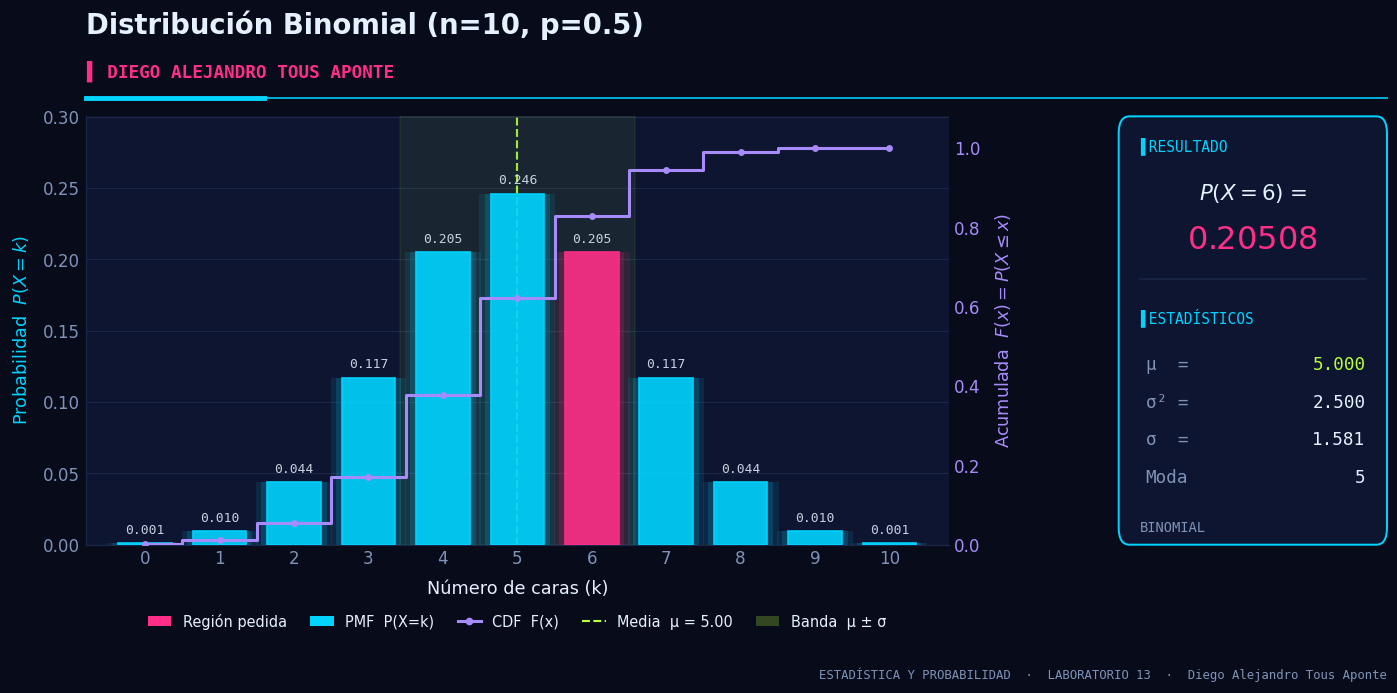

In [ ]:
# @title **Ejemplo 1. Probabilidad de obtener exactamente 6 caras**
n = 10 # Número de ensayos
p = 0.5 # Probabilidad de éxito
k = 6 # Número de éxitos

# Probabilidad de obtener exactamente 6 caras
prob_binom_1 = binom.pmf(k, n, p)
print(f"Probabilidad de obtener exactamente 6 caras: P(X = 6) = {prob_binom_1:.5f}")

# Gráfica de la Distribución Binomial (se resalta P(X = 6))
x_binom = np.arange(0, n + 1)
pmf_binom = binom.pmf(x_binom, n, p)

plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n}, p={p})",
                  xlabel="Número de caras (k)",
                  resaltar=(x_binom == 6),
                  etiqueta=f"$P(X=6) = {prob_binom_1:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 2 (del PDF):** La probabilidad de que una pieza fabricada por una empresa sea defectuosa es 0.1. Halla la probabilidad de que en una muestra de 25 piezas se encuentren a lo sumo cuatro piezas defectuosas. Haz un gráfico y sombrea P(X <= 4) cada rectángulo con rojo y dentro del gráfico coloca P(X <= 4).

[⬆️ Volver al inicio](#inicio)

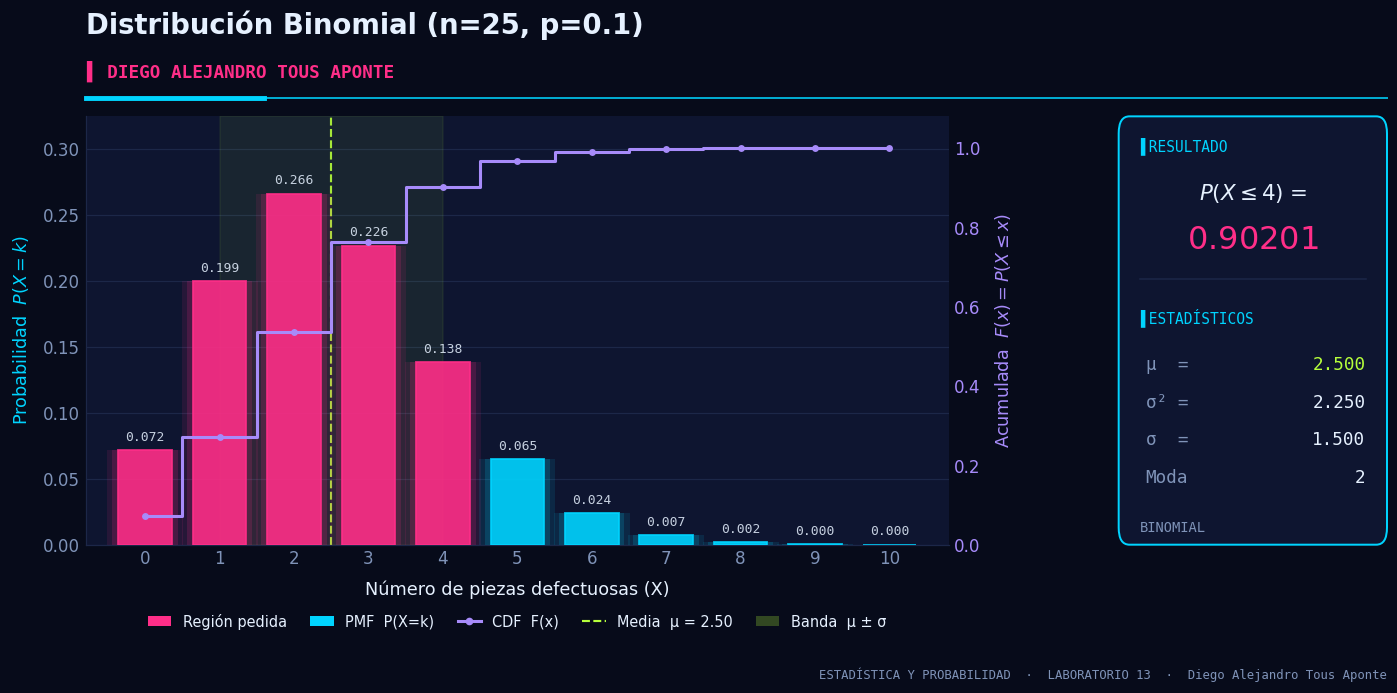

La probabilidad de que en una muestra de 25 piezas se encuentren a lo sumo 4 defectuosas es: 0.90201


In [ ]:
# @title **Ejemplo 2. Probabilidad de a lo sumo 4 piezas defectuosas**
n = 25 # Número de piezas
p = 0.1 # Probabilidad de que una pieza sea defectuosa
k = np.arange(0, n - 14) # Valores posibles de X: de 0 a 10 piezas defectuosas

# Calcula la probabilidad de obtener exactamente k piezas defectuosas
probabilidades = binom.pmf(k, n, p)

# Calcula la probabilidad de que haya a lo sumo 4 piezas defectuosas (P(X <= 4))
probabilidad_acumulada = binom.cdf(4, n, p)

# Gráfica de la distribución binomial (se sombrea P(X <= 4))
plot_distribution("Binomial", k, probabilidades, f"Distribución Binomial (n={n}, p={p})",
                  xlabel="Número de piezas defectuosas (X)",
                  momentos=(n * p, n * p * (1 - p)),
                  resaltar=(k <= 4),
                  etiqueta=f"$P(X \\leq 4) = {probabilidad_acumulada:.5f}$")

print(f"La probabilidad de que en una muestra de 25 piezas se encuentren a lo sumo 4 defectuosas es: {probabilidad_acumulada:.5f}")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 3 (del PDF):** El 60% de los Psicólogos de una facultad encuentran trabajo el primer año después de acabar la carrera. De los 100 Psicólogos en un curso, ¿Cuántos se espera que se coloque en el primer año? ¿Cuál es la varianza?

[⬆️ Volver al inicio](#inicio)

In [ ]:
# @title **Ejemplo 3. Número esperado de psicólogos que encuentran trabajo**
n = 100 # Número total de psicólogos
p = 0.6 # Probabilidad de encontrar trabajo en el primer año

# Calcular el número esperado de psicólogos que encontrarán trabajo
esperanza_binom = n * p

# Calcular la varianza
varianza_binom = n * p * (1 - p)

print(f"Se espera que {esperanza_binom:.0f} psicólogos encuentren trabajo en el primer año.")
print(f"La varianza es: {varianza_binom:.2f}")

Se espera que 60 psicólogos encuentren trabajo en el primer año.
La varianza es: 24.00


[⬆️ Volver al inicio](#inicio)

**Ejemplo 4 (del PDF):** Suponiendo que el 40% de los Comunicadores Sociales tengan Rh-, si tomamos una muestra de siete Comunicadores Sociales, (a) ¿Qué probabilidad hay de que todas sean Rh-? (b) ¿Y de que máximo cuatro sean Rh-? Haz un gráfico y sombrea P(X <= 4) cada rectángulo con rojo y dentro del gráfico coloca P(X <= 4) y en otro gráfico sombrea P(X = 7).

[⬆️ Volver al inicio](#inicio)

Probabilidad de que todas sean Rh-: P(X = 7) = 0.00164


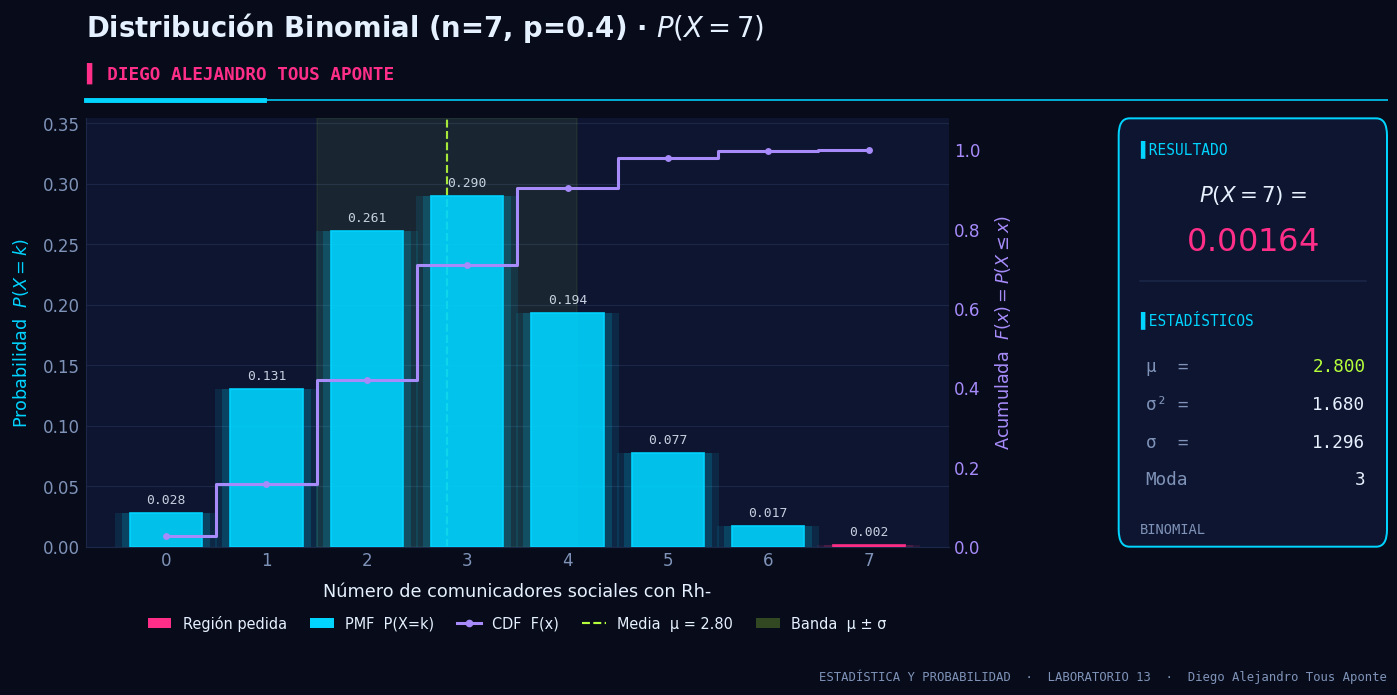

Probabilidad de que máximo cuatro sean Rh-: P(X <= 4) = 0.90374


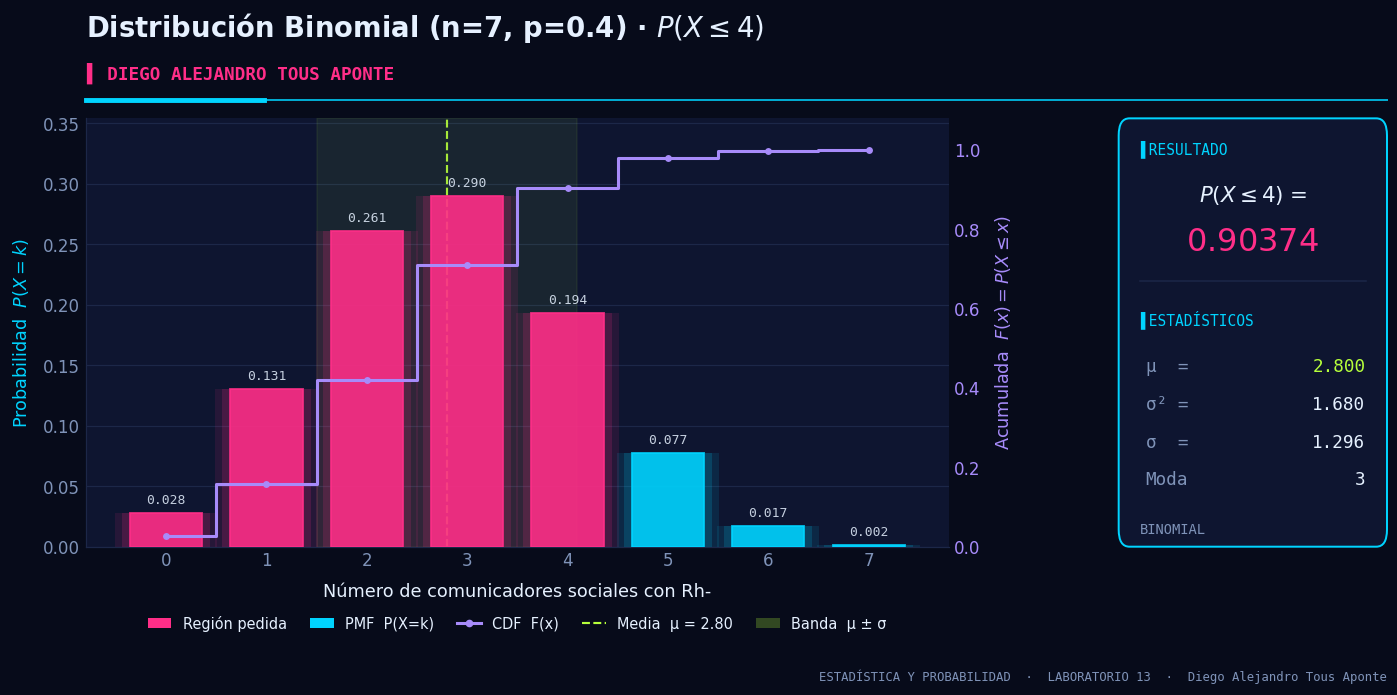

In [ ]:
# @title **Ejemplo 4. Probabilidades con Rh-**
n = 7 # Número de comunicadores sociales en la muestra
p = 0.4 # Probabilidad de que un comunicador social tenga Rh-

x_binom = np.arange(0, n + 1)
pmf_binom = binom.pmf(x_binom, n, p)

# (a) Probabilidad de que todas sean Rh-
prob_todas_rh_neg = binom.pmf(n, n, p)
print(f"Probabilidad de que todas sean Rh-: P(X = 7) = {prob_todas_rh_neg:.5f}")

# Gráfico sombreando P(X = 7)
plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n}, p={p}) · $P(X=7)$",
                  xlabel="Número de comunicadores sociales con Rh-",
                  resaltar=(x_binom == 7),
                  etiqueta=f"$P(X=7) = {prob_todas_rh_neg:.5f}$")

# (b) Probabilidad de que máximo cuatro sean Rh-
prob_maximo_cuatro_rh_neg = binom.cdf(4, n, p)
print(f"Probabilidad de que máximo cuatro sean Rh-: P(X <= 4) = {prob_maximo_cuatro_rh_neg:.5f}")

# Gráfico sombreando P(X <= 4)
plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n}, p={p}) · $P(X \\leq 4)$",
                  xlabel="Número de comunicadores sociales con Rh-",
                  resaltar=(x_binom <= 4),
                  etiqueta=f"$P(X \\leq 4) = {prob_maximo_cuatro_rh_neg:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 5 (del PDF):** Un laboratorio ha comprobado que el 25% de los que toman un determinado antibiótico sufren efectos secundarios. De una muestra de ocho enfermos que toman dicho antibiótico, halla la probabilidad de que sufran efectos secundarios al menos tres.

[⬆️ Volver al inicio](#inicio)

La probabilidad de que al menos tres enfermos sufran efectos secundarios es: 0.32146


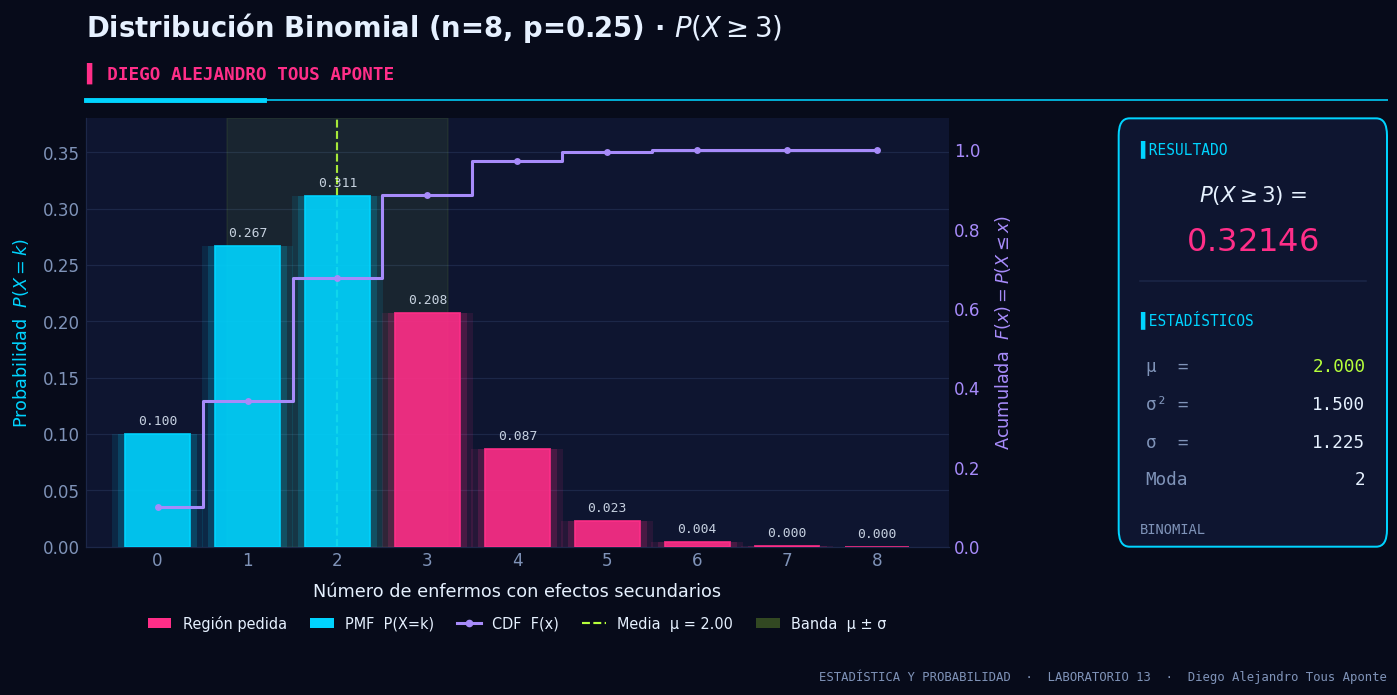

In [ ]:
# @title **Ejemplo 5. Probabilidad de al menos 3 efectos secundarios**
p = 0.25 # Probabilidad de sufrir efectos secundarios
n = 8 # Número de enfermos en la muestra

# Calcular la probabilidad de que al menos tres sufran efectos secundarios
# P(X >= 3) = 1 - P(X < 3) = 1 - [P(X = 0) + P(X = 1) + P(X = 2)]
prob_al_menos_tres = 1 - binom.cdf(2, n, p)

print(f"La probabilidad de que al menos tres enfermos sufran efectos secundarios es: {prob_al_menos_tres:.5f}")

# Gráfico sombreando P(X >= 3)
x_binom = np.arange(0, n + 1)
pmf_binom = binom.pmf(x_binom, n, p)

plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n}, p={p}) · $P(X \\geq 3)$",
                  xlabel="Número de enfermos con efectos secundarios",
                  resaltar=(x_binom >= 3),
                  etiqueta=f"$P(X \\geq 3) = {prob_al_menos_tres:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 6 (del PDF):** Un laboratorio ha comprobado que el 25% de los que toman un determinado antibiótico sufren efectos secundarios. De una muestra de ocho enfermos que toman dicho antibiótico, halla la probabilidad de que sufran efectos secundarios menos de 3.

[⬆️ Volver al inicio](#inicio)

La probabilidad de que menos de 3 enfermos sufran efectos secundarios es: 0.67854


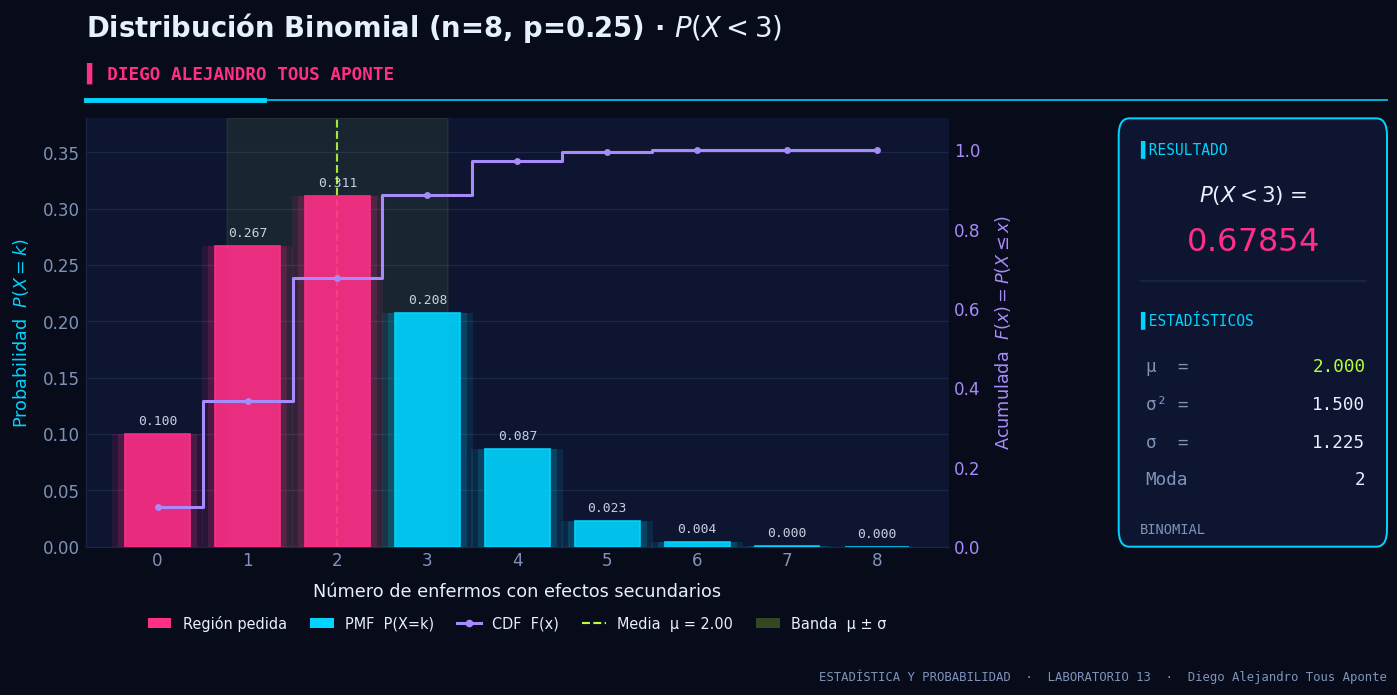

In [ ]:
# @title **Ejemplo 6. Probabilidad de menos de 3 efectos secundarios**
p = 0.25 # Probabilidad de sufrir efectos secundarios
n = 8 # Número de enfermos en la muestra

# Calcular la probabilidad de que menos de 3 sufran efectos secundarios
# P(X < 3) = P(X = 0) + P(X = 1) + P(X = 2)
prob_menos_de_tres = binom.cdf(2, n, p)

print(f"La probabilidad de que menos de 3 enfermos sufran efectos secundarios es: {prob_menos_de_tres:.5f}")

# Gráfico sombreando P(X < 3)
x_binom = np.arange(0, n + 1)
pmf_binom = binom.pmf(x_binom, n, p)

plot_distribution("Binomial", x_binom, pmf_binom, f"Distribución Binomial (n={n}, p={p}) · $P(X < 3)$",
                  xlabel="Número de enfermos con efectos secundarios",
                  resaltar=(x_binom < 3),
                  etiqueta=f"$P(X < 3) = {prob_menos_de_tres:.5f}$")

[⬆️ Volver al inicio](#inicio)

<a name="binneg"></a>

#### **3.3. Distribución Binomial Negativa**

**Definición:** Modela el número de fracasos que ocurren antes de obtener un número fijo de éxitos (*r*).

- **Función de Probabilidad:** $P(X=k) = \binom{k+r-1}{k} p^r (1-p)^{k}$, para $k = 0, 1, 2, \dots$
- **Media (Esperanza):** $E(X) = r(1-p) / p$
- **Varianza:** $Var(X) = r(1-p) / p^2$

**Ejemplo 1 (del PDF):** ¿Cuál es la probabilidad de obtener 5 éxitos antes de 3 fracasos si la probabilidad de éxito es p = 0.7?

[⬆️ Volver al inicio](#inicio)

In [ ]:
# @title **Ejemplo 1. Probabilidad de 5 éxitos antes de 3 fracasos**
r = 5 # Número de éxitos
p = 0.7 # Probabilidad de éxito
k = 3 # Número de fracasos antes de obtener 5 éxitos

# Probabilidad
prob_nbinom_1 = nbinom.pmf(k, r, p)
print(f"Probabilidad de obtener 5 éxitos antes de 3 fracasos: P(X=5) = {prob_nbinom_1:.5f}")

# Momentos
esperanza_nbinom = r * (1 - p) / p
varianza_nbinom = r * (1 - p) / (p ** 2)
desviacion_nbinom = np.sqrt(varianza_nbinom)

print(f"\nMomentos en el Modelo Binomial Negativo")
print(f"Esperanza:E(X) = {esperanza_nbinom:.2f}")
print(f"Varianza: V(X) = {varianza_nbinom:.2f}")
print(f"Desviación estándar: {desviacion_nbinom:.2f}")

Probabilidad de obtener 5 éxitos antes de 3 fracasos: P(X=5) = 0.15883

Momentos en el Modelo Binomial Negativo
Esperanza:E(X) = 2.14
Varianza: V(X) = 3.06
Desviación estándar: 1.75


[⬆️ Volver al inicio](#inicio)

**Ejemplo 2 (del PDF):** La probabilidad de un niño expuesto al COVID-19 se contagie es de 0.6. ¿Cuál es la probabilidad de que el 10° niño expuesto sea el tercero en contraerla?

[⬆️ Volver al inicio](#inicio)

In [ ]:
# @title **Ejemplo 2. Probabilidad de que el 10° niño sea el tercero en contagiarse**
n = 10 # Número de ensayos
r = 3 # Número de éxitos
p = 0.6 # Probabilidad de éxito
k = n - r # Número de fracasos antes de obtener 3 éxitos

# Probabilidad
prob_nbinom_2 = nbinom.pmf(k, r, p)
print(f"Probabilidad de que el 10° niño sea el tercero en contagiarse: {prob_nbinom_2:.5f}")

Probabilidad de que el 10° niño sea el tercero en contagiarse: 0.01274


[⬆️ Volver al inicio](#inicio)

<a name="poisson"></a>

#### **3.4. Distribución de Poisson**

**Definición:** Modela el número de eventos que ocurren en un intervalo de tiempo o espacio, dado un promedio de ocurrencia ($\lambda$).

- **Función de Probabilidad:** $P(X=k) = \frac{\lambda^k e^{-\lambda}}{k!}$, para $k = 0, 1, 2, \dots$
- **Media (Esperanza):** $E(X) = \lambda$
- **Varianza:** $Var(X) = \lambda$

**Ejemplo 1 (del PDF):** Una central telefónica recibe en promedio 2 llamadas por minuto. ¿Cuál es la probabilidad de que en un minuto se reciban exactamente 3 llamadas?

[⬆️ Volver al inicio](#inicio)

Probabilidad de recibir exactamente 3 llamadas: P(X=3) = 0.18045


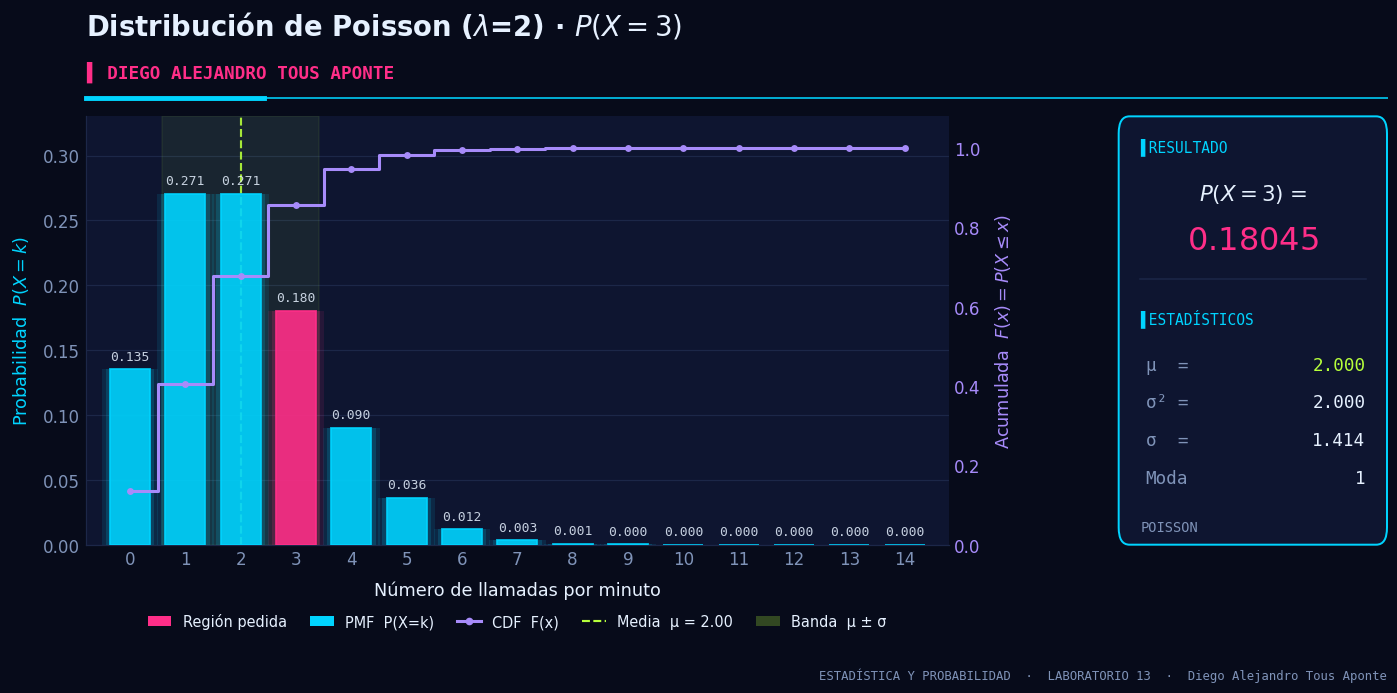

In [ ]:
# @title **Ejemplo 1. Probabilidad de recibir exactamente 3 llamadas**
lambda_poisson = 2 # Tasa promedio de ocurrencia
k = 3 # Número de eventos (llamadas)

# Probabilidad
prob_poisson_1 = poisson.pmf(k, lambda_poisson)
print(f"Probabilidad de recibir exactamente 3 llamadas: P(X=3) = {prob_poisson_1:.5f}")

# Gráfico sombreando P(X=3)
x_poisson = np.arange(0, 15)
pmf_poisson = poisson.pmf(x_poisson, lambda_poisson)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_poisson}) · $P(X=3)$",
                  momentos=(lambda_poisson, lambda_poisson),
                  xlabel="Número de llamadas por minuto",
                  resaltar=(x_poisson == 3),
                  etiqueta=f"$P(X=3) = {prob_poisson_1:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 2 (del PDF):** En la zona que rodea un punto kilométrico de una autovía hay una población de erizos. Se ha realizado un estudio por el que se ha deducido que los erizos cruzan la autovía a razón de 4 cada 30 minutos. La probabilidad de que 6 o más erizos crucen la autovía en una hora es: Dibuja la distribución de Poisson y sombrea el rectángulo con P(X>=6).

[⬆️ Volver al inicio](#inicio)

La probabilidad de que 6 o más erizos crucen la autovía en una hora es: 0.80876


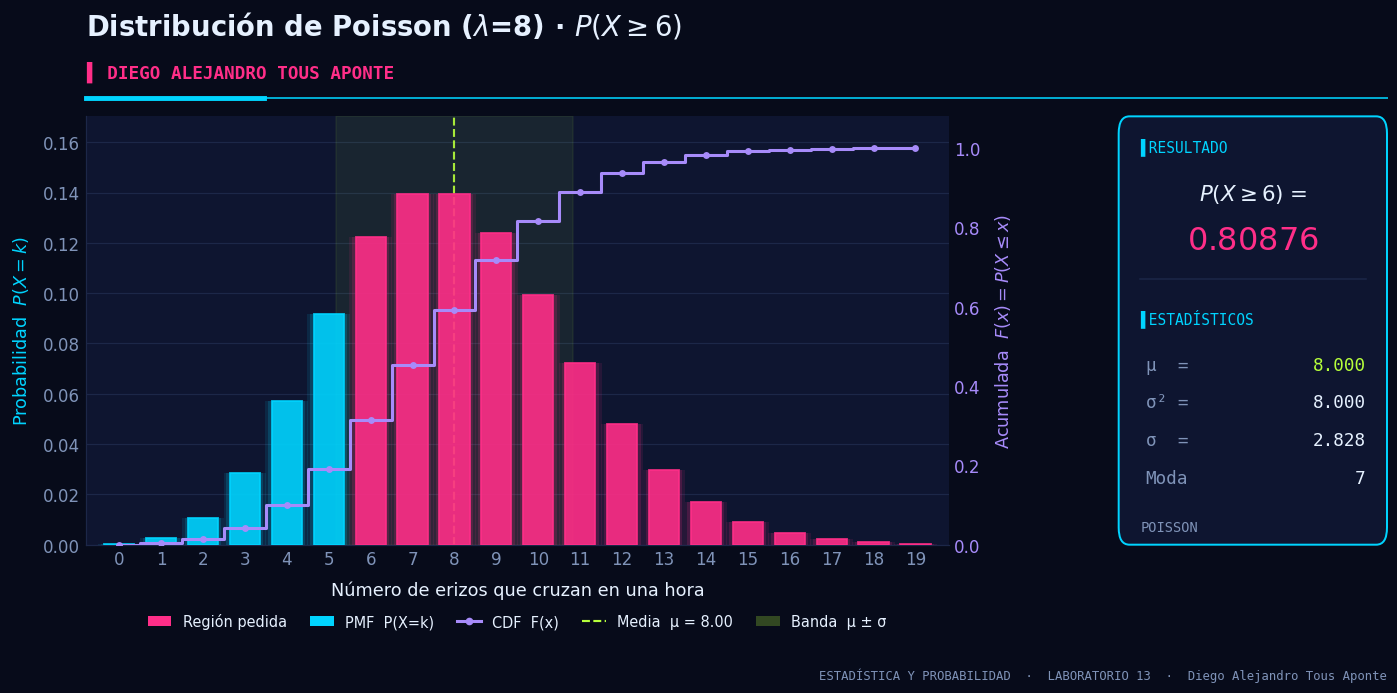

In [ ]:
# @title **Ejemplo 2. Probabilidad de 6 o más erizos en una hora**
lambda_poisson = 8 # Tasa promedio de erizos que cruzan en una hora (4 erizos/30min * 2)
prob_6_o_mas = 1 - poisson.cdf(5, lambda_poisson) # P(X >= 6) = 1 - P(X <= 5)

print(f"La probabilidad de que 6 o más erizos crucen la autovía en una hora es: {prob_6_o_mas:.5f}")

# Gráfico sombreando P(X >= 6)
x_poisson = np.arange(0, 20)
pmf_poisson = poisson.pmf(x_poisson, lambda_poisson)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_poisson}) · $P(X \\geq 6)$",
                  momentos=(lambda_poisson, lambda_poisson),
                  xlabel="Número de erizos que cruzan en una hora",
                  resaltar=(x_poisson >= 6),
                  etiqueta=f"$P(X \\geq 6) = {prob_6_o_mas:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 3 (del PDF):** En una carretera se producen un promedio de 2 accidentes anuales. Calcula la probabilidad de que estos cinco años se produzcan más de 3 accidentes.

[⬆️ Volver al inicio](#inicio)

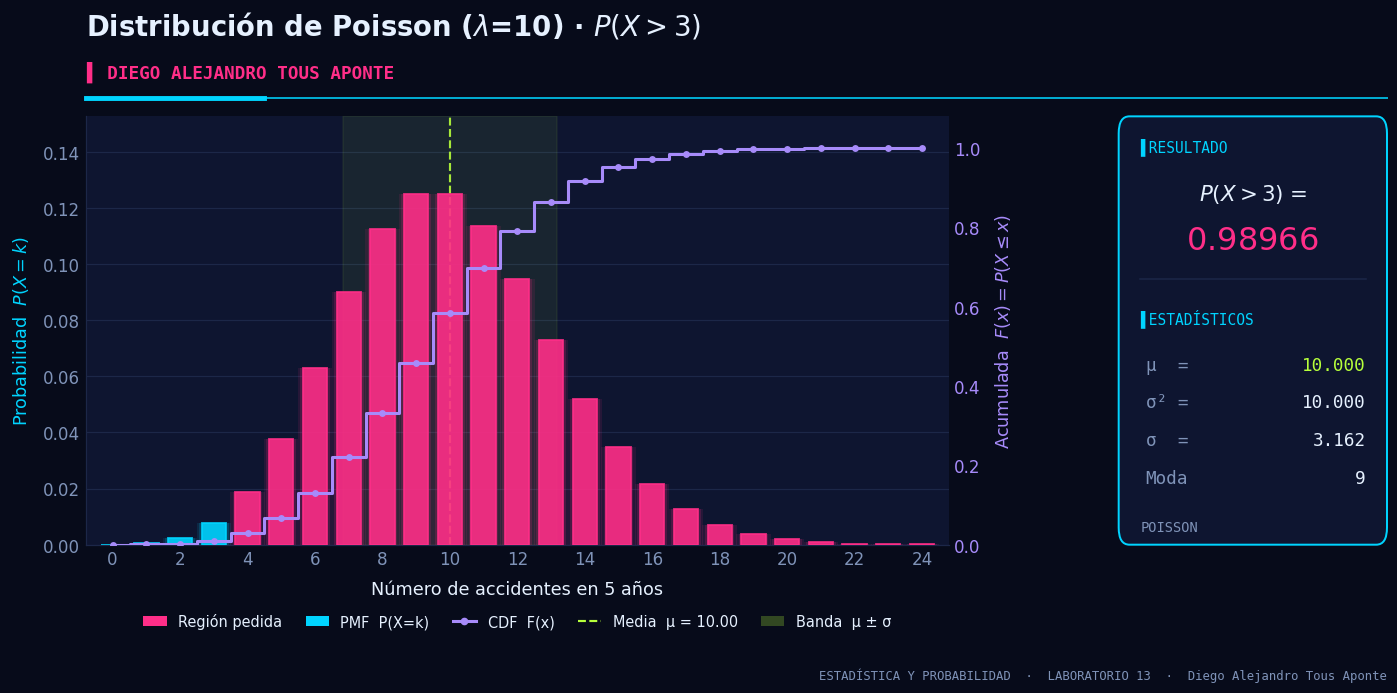

In [ ]:
# @title **Ejemplo 3. Probabilidad de más de 3 accidentes en 5 años**
lambda_poisson = 2 # Promedio de accidentes por año
lambda_5_years = lambda_poisson * 5 # Tasa promedio de accidentes en 5 años

# Calcular la probabilidad de que en 5 años se produzcan más de 3 accidentes
prob_mas_de_3 = 1 - poisson.cdf(3, lambda_5_years) # P(X > 3) = 1 - P(X <= 3)

# Gráfico sombreando P(X > 3)
x_poisson = np.arange(0, 25)
pmf_poisson = poisson.pmf(x_poisson, lambda_5_years)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_5_years}) · $P(X > 3)$",
                  momentos=(lambda_5_years, lambda_5_years),
                  xlabel="Número de accidentes en 5 años",
                  resaltar=(x_poisson > 3),
                  etiqueta=f"$P(X > 3) = {prob_mas_de_3:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 4 (del PDF):** En la hora punta de la mañana en un semáforo pasan una media de 10 coches por minuto. ¿Cuál es la probabilidad de que pasen exactamente 16 coches en 2 minutos?

[⬆️ Volver al inicio](#inicio)

La probabilidad de que pasen exactamente 16 coches en 2 minutos es: 0.06456


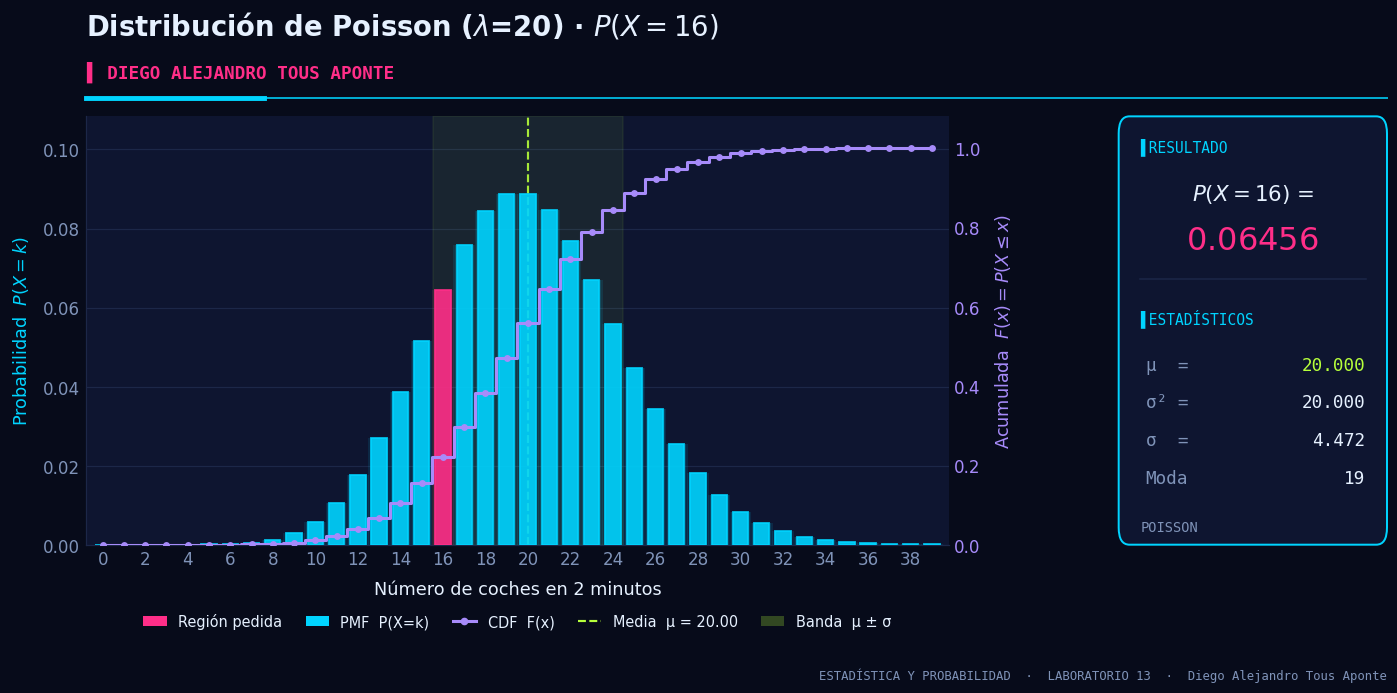

In [ ]:
# @title **Ejemplo 4. Probabilidad de 16 coches en 2 minutos**
lambda_poisson = 10 * 2 # Tasa promedio de coches en 2 minutos
k = 16 # Número de coches que queremos calcular la probabilidad

# Probabilidad de que pasen exactamente 16 coches en 2 minutos
prob_poisson = poisson.pmf(k, lambda_poisson)
print(f"La probabilidad de que pasen exactamente 16 coches en 2 minutos es: {prob_poisson:.5f}")

# Gráfico sombreando P(X=16)
x_poisson = np.arange(0, 40)
pmf_poisson = poisson.pmf(x_poisson, lambda_poisson)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_poisson}) · $P(X=16)$",
                  momentos=(lambda_poisson, lambda_poisson),
                  xlabel="Número de coches en 2 minutos",
                  resaltar=(x_poisson == k),
                  etiqueta=f"$P(X=16) = {prob_poisson:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 5 (del PDF):** Si un banco recibe en promedio 6 cheques sin fondo por día, ¿cuáles son las probabilidades de que reciba: a. cuatro cheques sin fondo en un día dado, b. cincuenta cheques sin fondo en una semana, c. diez cheques sin fondo en 12 horas, d. 5 cheques sin fondos en 4 horas?

[⬆️ Volver al inicio](#inicio)

a. Probabilidad de 4 cheques sin fondo en un día: 0.13385


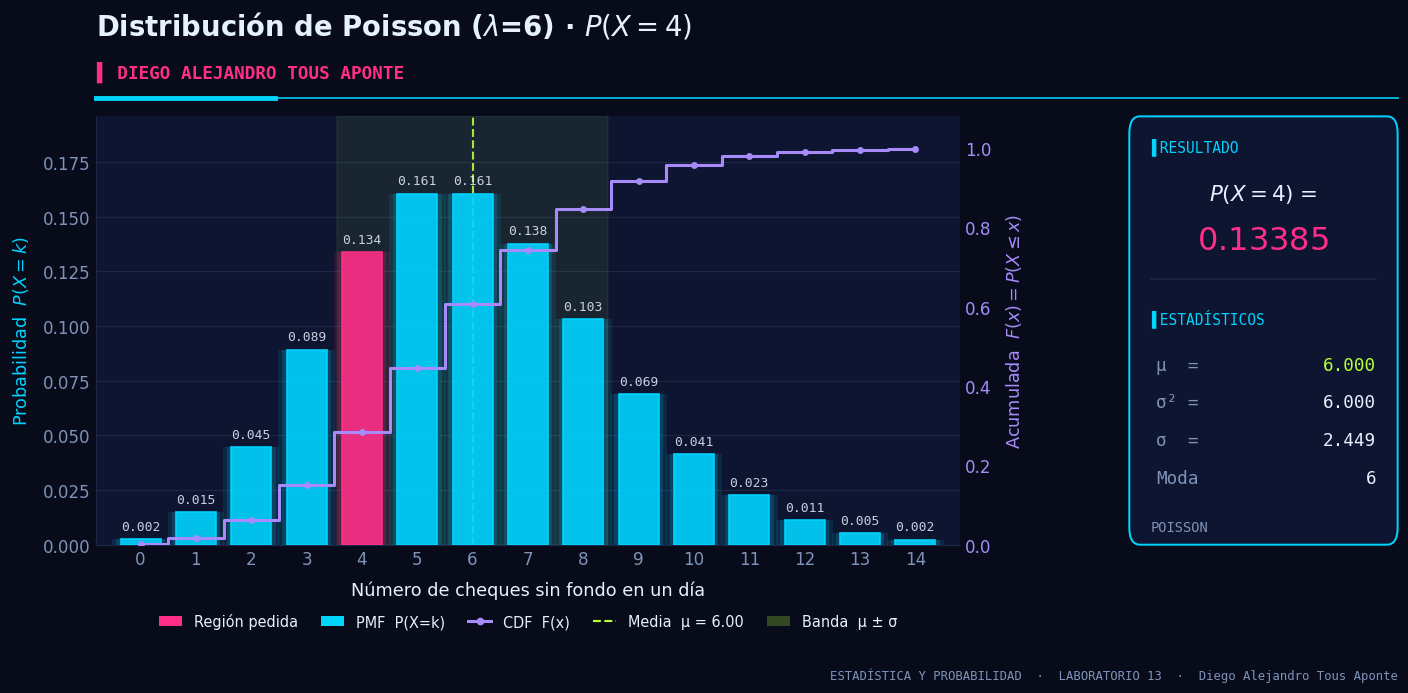

b. Probabilidad de 50 cheques sin fondo en una semana: 0.02748


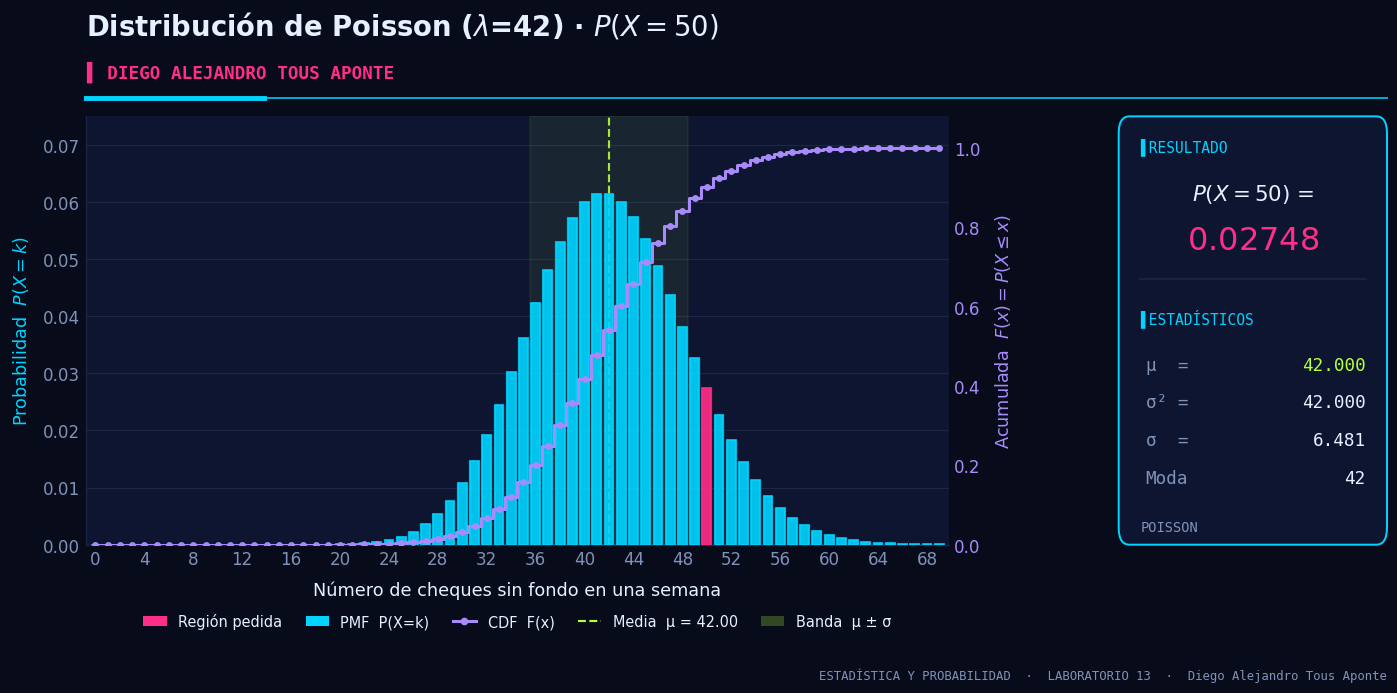

c. Probabilidad de 10 cheques sin fondo en 12 horas: 0.00081


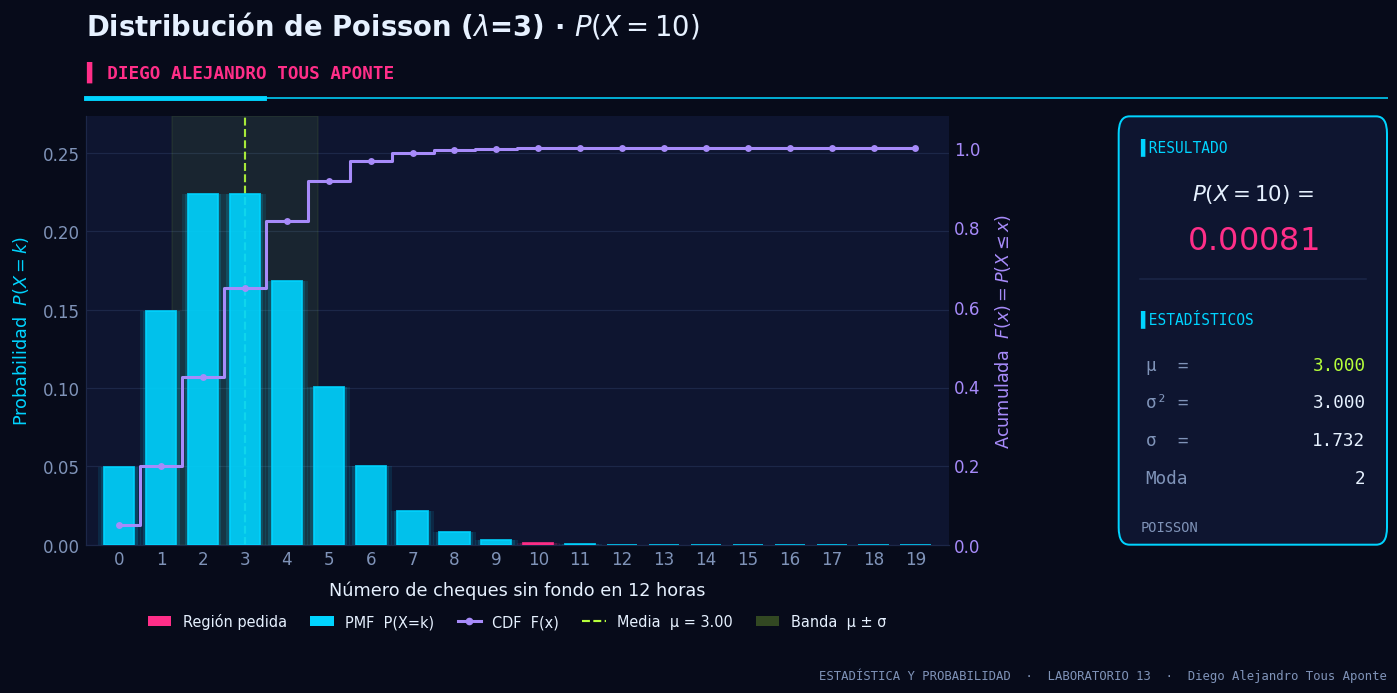

d. Probabilidad de 5 cheques sin fondo en 4 horas: 0.00307


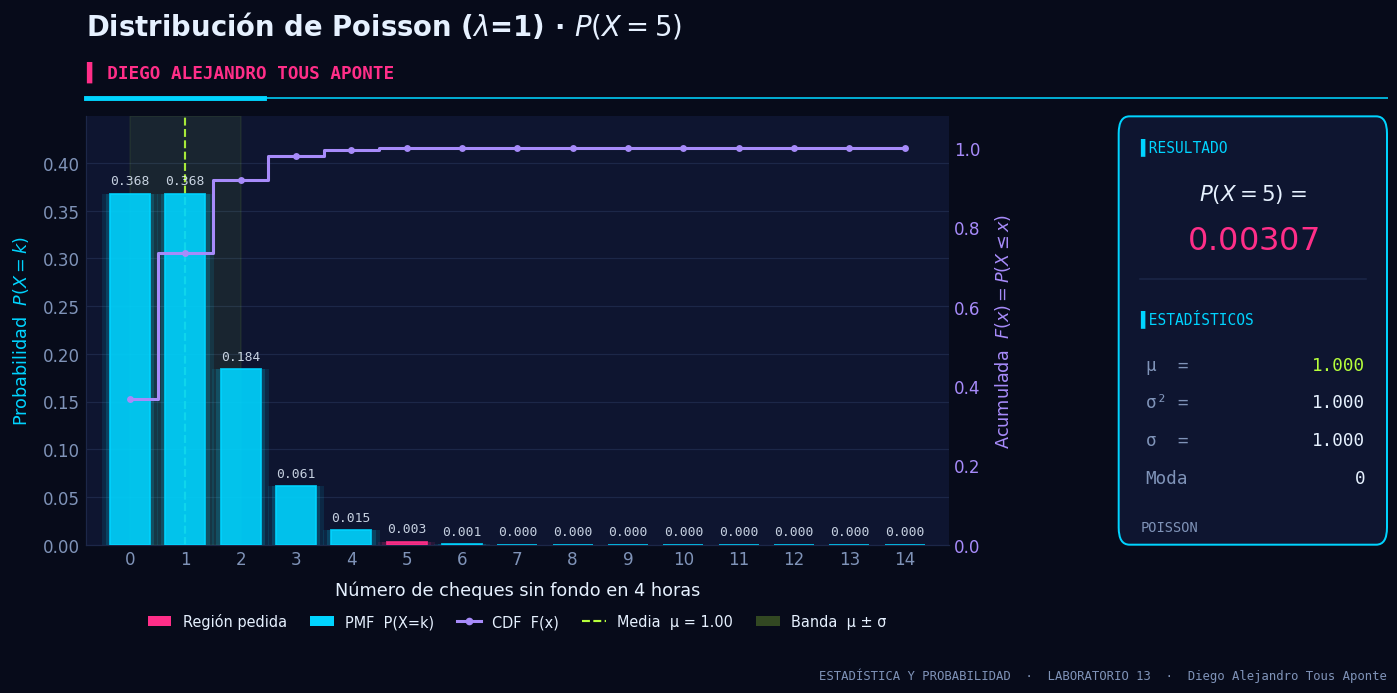

In [ ]:
# @title **Ejemplo 5. Probabilidades con cheques sin fondo**
lambda_dia = 6 # Promedio de cheques sin fondo por día

# a. Cuatro cheques sin fondo en un día dado
k_a = 4
prob_a = poisson.pmf(k_a, lambda_dia)
print(f"a. Probabilidad de 4 cheques sin fondo en un día: {prob_a:.5f}")

x_poisson_a = np.arange(0, 15)
plot_distribution("Poisson", x_poisson_a, poisson.pmf(x_poisson_a, lambda_dia),
                  f"Distribución de Poisson ($\\lambda$={lambda_dia}) · $P(X=4)$",
                  momentos=(lambda_dia, lambda_dia),
                  xlabel="Número de cheques sin fondo en un día",
                  resaltar=(x_poisson_a == k_a),
                  etiqueta=f"$P(X=4) = {prob_a:.5f}$")

# b. Cincuenta cheques sin fondo en una semana
lambda_semana = lambda_dia * 7
k_b = 50
prob_b = poisson.pmf(k_b, lambda_semana)
print(f"b. Probabilidad de 50 cheques sin fondo en una semana: {prob_b:.5f}")

x_poisson_b = np.arange(0, 70)
plot_distribution("Poisson", x_poisson_b, poisson.pmf(x_poisson_b, lambda_semana),
                  f"Distribución de Poisson ($\\lambda$={lambda_semana}) · $P(X=50)$",
                  momentos=(lambda_semana, lambda_semana),
                  xlabel="Número de cheques sin fondo en una semana",
                  resaltar=(x_poisson_b == k_b),
                  etiqueta=f"$P(X=50) = {prob_b:.5f}$")

# c. Diez cheques sin fondo en 12 horas
lambda_12horas = lambda_dia * 0.5
k_c = 10
prob_c = poisson.pmf(k_c, lambda_12horas)
print(f"c. Probabilidad de 10 cheques sin fondo en 12 horas: {prob_c:.5f}")

x_poisson_c = np.arange(0, 20)
plot_distribution("Poisson", x_poisson_c, poisson.pmf(x_poisson_c, lambda_12horas),
                  f"Distribución de Poisson ($\\lambda$={lambda_12horas:g}) · $P(X=10)$",
                  momentos=(lambda_12horas, lambda_12horas),
                  xlabel="Número de cheques sin fondo en 12 horas",
                  resaltar=(x_poisson_c == k_c),
                  etiqueta=f"$P(X=10) = {prob_c:.5f}$")

# d. 5 cheques sin fondos en 4 horas
lambda_4horas = lambda_dia * (4/24)
k_d = 5
prob_d = poisson.pmf(k_d, lambda_4horas)
print(f"d. Probabilidad de 5 cheques sin fondo en 4 horas: {prob_d:.5f}")

x_poisson_d = np.arange(0, 15)
plot_distribution("Poisson", x_poisson_d, poisson.pmf(x_poisson_d, lambda_4horas),
                  f"Distribución de Poisson ($\\lambda$={lambda_4horas:g}) · $P(X=5)$",
                  momentos=(lambda_4horas, lambda_4horas),
                  xlabel="Número de cheques sin fondo en 4 horas",
                  resaltar=(x_poisson_d == k_d),
                  etiqueta=f"$P(X=5) = {prob_d:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 6 (del PDF):** En una empresa el término medio de accidentes es de 5 por mes. Calcular la probabilidad de que como mínimo ocurran 2 accidentes en un mes.

[⬆️ Volver al inicio](#inicio)

La probabilidad de que ocurran como mínimo 2 accidentes en un mes es: 0.95957


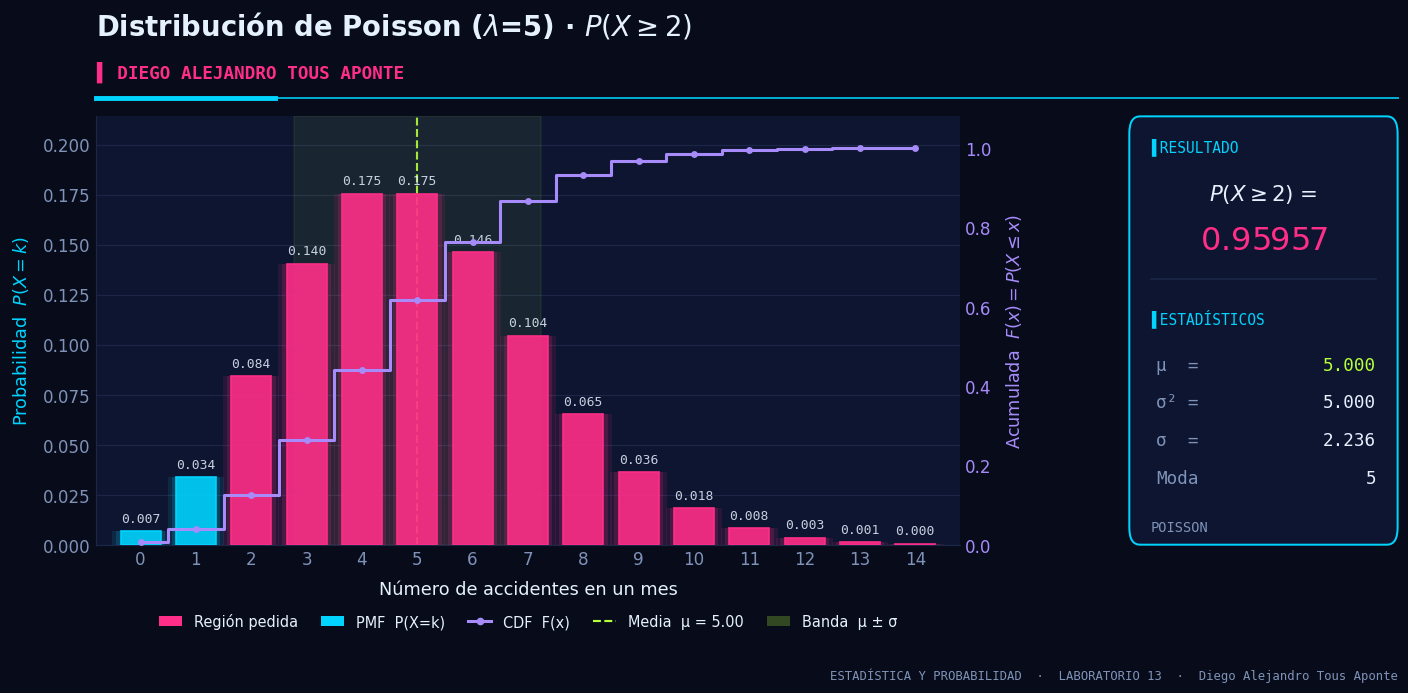

In [ ]:
# @title **Ejemplo 6. Probabilidad de al menos 2 accidentes en un mes**
lambda_poisson = 5 # Tasa promedio de accidentes por mes

# La probabilidad de que ocurran como mínimo 2 accidentes es
# P(X >= 2) = 1 - P(X < 2) = 1 - [P(X = 0) + P(X = 1)]
prob_poisson_0 = poisson.pmf(0, lambda_poisson)
prob_poisson_1 = poisson.pmf(1, lambda_poisson)
prob_al_menos_2 = 1 - (prob_poisson_0 + prob_poisson_1)

print(f"La probabilidad de que ocurran como mínimo 2 accidentes en un mes es: {prob_al_menos_2:.5f}")

# Gráfico
x_poisson = np.arange(0, 15)
pmf_poisson = poisson.pmf(x_poisson, lambda_poisson)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_poisson}) · $P(X \\geq 2)$",
                  momentos=(lambda_poisson, lambda_poisson),
                  xlabel="Número de accidentes en un mes",
                  resaltar=(x_poisson >= 2),
                  etiqueta=f"$P(X \\geq 2) = {prob_al_menos_2:.5f}$")

[⬆️ Volver al inicio](#inicio)

**Ejemplo 7 (del PDF):** En una empresa el término medio de accidentes es de 5 por mes. Calcular la probabilidad de que ocurran 8 accidentes en un trimestre.

[⬆️ Volver al inicio](#inicio)

La probabilidad de que ocurran 8 accidentes en un trimestre es: 0.01944


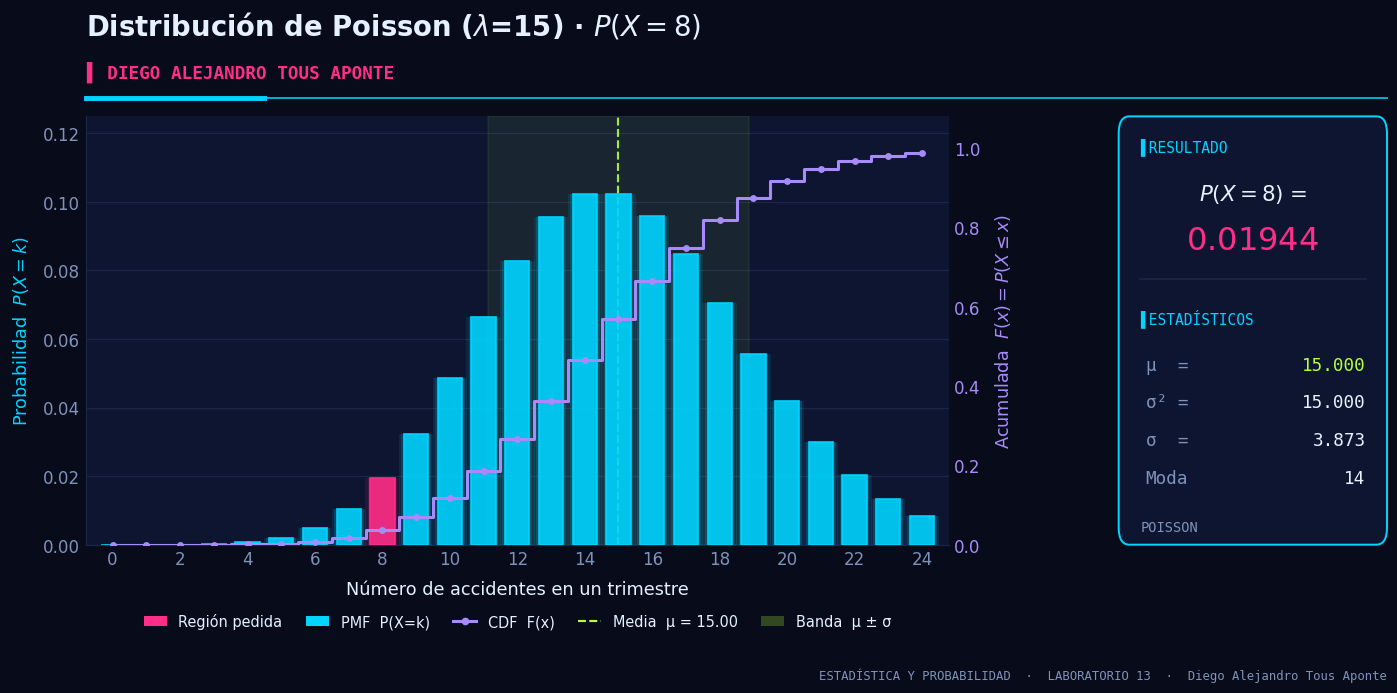

In [ ]:
# @title **Ejemplo 7. Probabilidad de 8 accidentes en un trimestre**
lambda_poisson = 5 * 3 # Tasa promedio de accidentes por trimestre
k = 8 # Número de accidentes

# La probabilidad de que ocurran exactamente 8 accidentes en un trimestre es P(X = 8)
prob_poisson_8 = poisson.pmf(k, lambda_poisson)
print(f"La probabilidad de que ocurran 8 accidentes en un trimestre es: {prob_poisson_8:.5f}")

# Gráfico
x_poisson = np.arange(0, 25)
pmf_poisson = poisson.pmf(x_poisson, lambda_poisson)

plot_distribution("Poisson", x_poisson, pmf_poisson, f"Distribución de Poisson ($\\lambda$={lambda_poisson}) · $P(X=8)$",
                  momentos=(lambda_poisson, lambda_poisson),
                  xlabel="Número de accidentes en un trimestre",
                  resaltar=(x_poisson == k),
                  etiqueta=f"$P(X=8) = {prob_poisson_8:.5f}$")

[⬆️ Volver al inicio](#inicio)

<a name="hipergeo"></a>

#### **3.5. Distribución Hipergeométrica**

**Definición:** Modela el número de éxitos en una muestra de tamaño *n*, extraída **sin reemplazo** de una población finita de tamaño *N*, que contiene *K* éxitos.

- **Función de Probabilidad:** $P(X=k) = \frac{\binom{K}{k} \binom{N-K}{n-k}}{\binom{N}{n}}$, donde *k* está limitado por $\max(0, n+K-N) \le k \le \min(n, K)$.
- **Media (Esperanza):** $E(X) = n \cdot \frac{K}{N}$
- **Varianza:** $Var(X) = n \cdot \frac{K}{N} \cdot \left(1 - \frac{K}{N}\right) \cdot \frac{N-n}{N-1}$

**Ejemplo 1 (del PDF):** Una urna contiene 10 bolas rojas y 20 bolas azules. Se seleccionan 5 bolas sin reemplazo. ¿Cuál es la probabilidad de seleccionar exactamente 3 bolas rojas?

[⬆️ Volver al inicio](#inicio)

In [ ]:
# @title **Ejemplo 1. Probabilidad de seleccionar exactamente 3 bolas rojas**
N = 30 # Tamaño de la población (total de bolas)
K = 10 # Número de éxitos en la población (bolas rojas)
n = 5 # Tamaño de la muestra
k = 3 # Número de éxitos en la muestra (bolas rojas)

# Probabilidad
prob_hyper_1 = hypergeom.pmf(k, N, K, n)
print(f"Probabilidad de seleccionar exactamente 3 bolas rojas: P(X=3) = {prob_hyper_1:.5f}")

# Momentos
esperanza_hyper = n * (K / N)
varianza_hyper = n * (K / N) * ((N - K) / N) * ((N - n) / (N - 1))
desviacion_hyper = np.sqrt(varianza_hyper)

print(f"\nMomentos en el Modelo Hipergeométrico")
print(f"Esperanza:E(X) = {esperanza_hyper:.2f}")
print(f"Varianza: V(X) = {varianza_hyper:.2f}")
print(f"Desviación estándar: {desviacion_hyper:.2f}")

Probabilidad de seleccionar exactamente 3 bolas rojas: P(X=3) = 0.15999

Momentos en el Modelo Hipergeométrico
Esperanza:E(X) = 1.67
Varianza: V(X) = 0.96
Desviación estándar: 0.98


[⬆️ Volver al inicio](#inicio)

<a name="ejercicios"></a>

### **Parte 4: Ejercicios Propuestos**

Resuelve los siguientes problemas utilizando el código que has aprendido. Para cada uno, calcula la probabilidad y grafica la distribución.

1.  **Binomial:** Un estudiante responde un examen de 15 preguntas de opción múltiple (4 opciones cada una) al azar. ¿Cuál es la probabilidad de que acierte exactamente 6 preguntas? ¿Y de que acierte 5 o menos?
2.  **Poisson:** En un sitio web, se reciben en promedio 3 visitas por minuto. ¿Cuál es la probabilidad de recibir exactamente 5 visitas en un minuto? ¿Y de recibir 2 o menos?
3.  **Hipergeométrica:** Un lote de 50 piezas contiene 10 defectuosas. Se seleccionan 8 piezas al azar sin reemplazo. ¿Cuál es la probabilidad de encontrar exactamente 2 defectuosas en la muestra?
4.  **Binomial Negativa:** Una máquina produce piezas con una probabilidad de defecto del 5%. ¿Cuál es la probabilidad de que la tercera pieza defectuosa sea la décima producida?

**Entregable:**
Comparte tu notebook de Google Colab con los ejercicios resueltos y sus respectivas gráficas.

In [ ]:
# @title **Ejercicio 1. Escribe tu solución aquí**
# Calcula la probabilidad y grafica la distribución de este ejercicio.

In [ ]:
# @title **Ejercicio 2. Escribe tu solución aquí**
# Calcula la probabilidad y grafica la distribución de este ejercicio.

In [ ]:
# @title **Ejercicio 3. Escribe tu solución aquí**
# Calcula la probabilidad y grafica la distribución de este ejercicio.

In [ ]:
# @title **Ejercicio 4. Escribe tu solución aquí**
# Calcula la probabilidad y grafica la distribución de este ejercicio.

[⬆️ Volver al inicio](#inicio)

[⬆️ Volver al inicio](#inicio)